# LAB 10 — K-Means Clustering
## Finding Customer Segments, Choosing K and Avoiding the Traps on Real Data

## Student Information
- **Name: Saba Noor**
- **Student ID: 023-24-0278**
- **Section: H**
- **GitHub: https://github.com/SABANOOR1/Machine-Learning**
- **Kaggle: https://www.kaggle.com/sabajaffar**
- **Dataset:** Mall Customers (Kaggle) + Wine (UCI)
- **Dataset Source:** https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python and https://archive.ics.uci.edu/dataset/109/wine

### Before You Start
- You studied K-Means in the lecture. This notebook does not teach it again; it makes you use it, test it and question it.
- There is **no target column**: no train/test split and no accuracy. Judge results by distances, silhouette, plots and common sense.
- Use `SEED = 42`. Write an interpretation under every table and plot. Place `Mall_Customers.csv` in the same folder as this notebook.
- `from sklearn.datasets import load_wine` loads the Wine data (no download needed).


---

## Part 0 — Setup and First Look (10 minutes)

Today there is no target column. The Mall Customers data has no 'right answer' for each customer, so we do not split into train and test and we cannot use accuracy. You will find groups with K-Means (your lecture) and judge them by distance, silhouette and common sense.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Unsupervised learning | Learning from data that has no labels. The goal is to find structure (groups), not to predict a column. | `No y, no train_test_split.` |
| Cluster | A group of points that are close to each other and far from the other groups. | `model.labels_ gives the cluster number of every row.` |
| Feature | One column used to describe each row (here Age, Income, Spending). | `df[['Income','Spending']].values` |


**First cell:** import everything you need (NumPy, Pandas, Matplotlib, KMeans, StandardScaler, PCA, load_wine, silhouette_score, silhouette_samples, adjusted_rand_score) and set `SEED = 42`.

In [4]:
# YOUR CODE HERE
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler 
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.datasets import load_wine
from sklearn.metrics import (silhouette_score, silhouette_samples, adjusted_rand_score)
SEED = 42

### Task 0.1 — Load and check the data

Load Mall_Customers.csv and understand it in one cell.

1. Load the CSV. Rename 'Annual Income (k$)' to Income and 'Spending Score (1-100)' to Spending (shorter names).
2. Print the shape, the number of missing values, the number of duplicate rows and the count of each Gender.
3. Show describe() for Age, Income and Spending.


In [5]:
# YOUR CODE HERE
df=pd.read_csv("Mall_customers.csv")
df.rename(columns={
    "Annual Income (k$)": "Income",
    "Spending Score (1-100)": "Spending"
},inplace=True    
)
print(df.shape)
print(df.isnull().sum())
print(df["Gender"].value_counts())
print(df.duplicated().sum())
print(df[['Age','Income','Spending']].describe())

(200, 5)
CustomerID    0
Gender        0
Age           0
Income        0
Spending      0
dtype: int64
Gender
Female    112
Male       88
Name: count, dtype: int64
0
              Age      Income    Spending
count  200.000000  200.000000  200.000000
mean    38.850000   60.560000   50.200000
std     13.969007   26.264721   25.823522
min     18.000000   15.000000    1.000000
25%     28.750000   41.500000   34.750000
50%     36.000000   61.500000   50.000000
75%     49.000000   78.000000   73.000000
max     70.000000  137.000000   99.000000


### Task 0.2 — Look at the data before clustering

Use your eyes first: draw three scatter plots side by side.

1. Draw Spending vs Income, Spending vs Age and Income vs Age (one row of three plots, axis labels and titles).


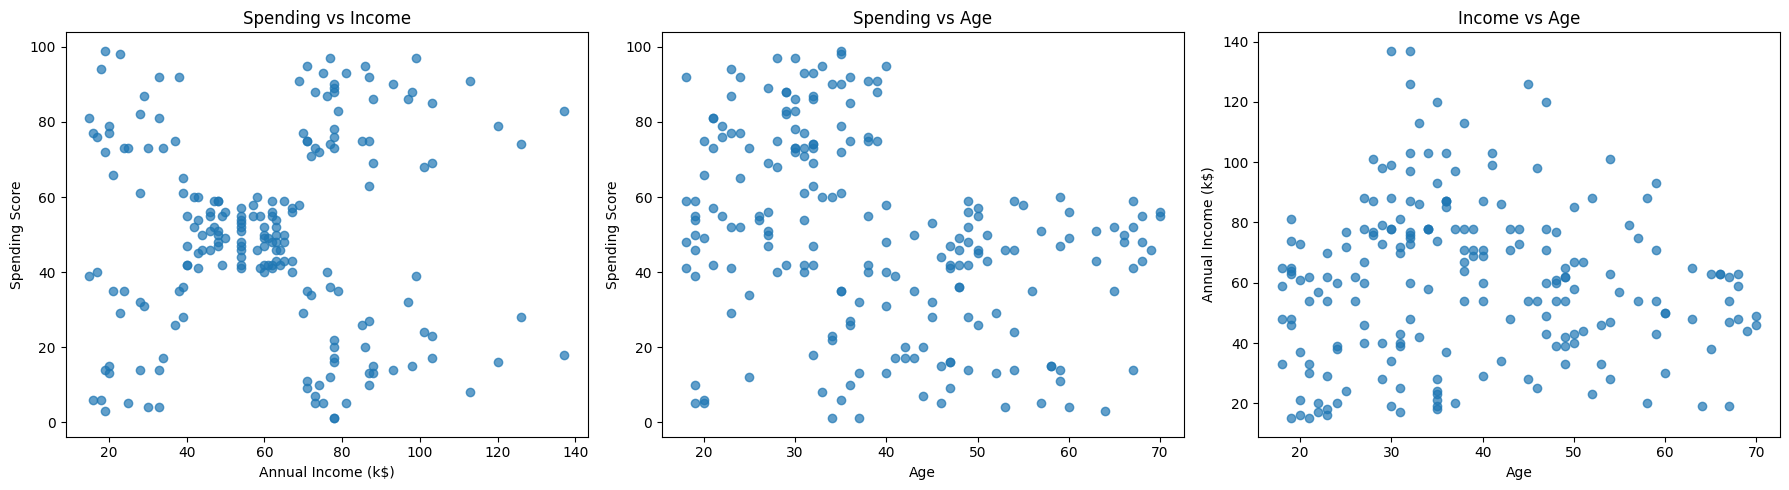

In [6]:
# YOUR CODE HERE
fig, axes=plt.subplots(1,3,figsize=(18,5))

axes[0].scatter(df['Income'], df['Spending'], alpha=0.7)
axes[0].set_title('Spending vs Income')
axes[0].set_xlabel('Annual Income (k$)')
axes[0].set_ylabel('Spending Score')

axes[1].scatter(df['Age'], df['Spending'], alpha=0.7)
axes[1].set_title('Spending vs Age')
axes[1].set_xlabel('Age')
axes[1].set_ylabel('Spending Score')

axes[2].scatter(df['Age'], df['Income'], alpha=0.7)
axes[2].set_title('Income vs Age')
axes[2].set_xlabel('Age')
axes[2].set_ylabel('Annual Income (k$)')

plt.tight_layout()
plt.show()

**Questions** (answer with your own numbers)

(a) How many groups can you see by eye in each of the three plots? Which plot shows the groups most clearly?

(b) Why can we not use accuracy or a train/test split to judge a clustering result?



**Your answers:**

(a)

**Plot 1: 5 groups**

**Plot 2: 2 groups**

**Plot 3: 1 group**

Plot 1 shows the groups most clearly.

(b) We cannot use accuracy or a train/test split in the usual way for clustering because clustering is an unsupervised learning technique, whereas accuracy and traditional train/test evaluation are mainly designed for supervised learning.



---

## Part 1 — K-Means From Scratch (35 minutes)

In the lecture you did K-Means by hand. Here you turn your pen-and-paper steps into code, check your answers against the lecture slides, and then build your own K-Means function and compare it with scikit-learn. Using KMeans() inside your own function is not allowed.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| K | The number of clusters. You choose it before running. | `KMeans(n_clusters=5)` |
| Centroid | The centre (mean) of a cluster. It is a point, not always a real row. | `model.cluster_centers_` |
| Distance | 1 feature: |x - m|. 2 or more features: Euclidean, sqrt of the sum of squared differences. | `np.abs(a-b)  or  np.sqrt(((a-b)**2).sum(axis=1))` |
| Assign step | Give each point to its nearest centroid. | `d.argmin(axis=1)` |
| Update step | Move each centroid to the mean of the points assigned to it. | `X[labels==k].mean(axis=0)` |
| Convergence | Stop when no point changes cluster (centroids stop moving). | `np.allclose(new_c, c)` |
| Inertia | Sum of squared distances from every point to its own centroid. Smaller = tighter clusters. | `model.inertia_` |
| Broadcasting | NumPy trick: x[:, None] - m[None, :] gives every point-to-centroid difference in one line. | `x[:, None, :] - C[None, :, :]` |


### Task 1.1 — Lecture Example 1 in code (one feature)

Reproduce the 9-number example from the lecture (2, 4, 10, 12, 3, 20, 30, 11, 25) with K = 2 and starting centroids 4 and 11.

1. Write a loop that, in every iteration, computes the distances, assigns the clusters, updates the centroids and prints both clusters and the new centroids.
2. Stop when no centroid changes. Print the final centroids and the inertia.
3. Compare with the lecture slides (final centroids 7 and 25, inertia 150).

**Hints:**
- Distance matrix: np.abs(x[:, None] - m[None, :]) has shape (9, 2).
- Cluster of each point: dist.argmin(axis=1).


In [7]:
# YOUR CODE HERE

x = np.array([2, 4, 10, 12, 3, 20, 30, 11, 25])

m = np.array([4.0, 11.0])

K = 2
iteration = 1

while True:
    print(f"\nIteration {iteration}")

    dist = np.abs(x[:, None] - m[None, :])

    clusters = dist.argmin(axis=1)

    new_m = np.array([
        x[clusters == k].mean() for k in range(K)
    ])

    for k in range(K):
        print(f"Cluster {k}: {x[clusters == k]}")

    print("Old centroids:", m)
    print("New centroids:", new_m)

    if np.allclose(m, new_m):
        m = new_m
        print("\nCentroids have stopped changing!")
        break

    m = new_m
    iteration += 1

print("\nFinal Centroids:", m)

inertia = np.sum((x - m[clusters]) ** 2)

print("Final Inertia:", inertia)


Iteration 1
Cluster 0: [2 4 3]
Cluster 1: [10 12 20 30 11 25]
Old centroids: [ 4. 11.]
New centroids: [ 3. 18.]

Iteration 2
Cluster 0: [ 2  4 10  3]
Cluster 1: [12 20 30 11 25]
Old centroids: [ 3. 18.]
New centroids: [ 4.75 19.6 ]

Iteration 3
Cluster 0: [ 2  4 10 12  3 11]
Cluster 1: [20 30 25]
Old centroids: [ 4.75 19.6 ]
New centroids: [ 7. 25.]

Iteration 4
Cluster 0: [ 2  4 10 12  3 11]
Cluster 1: [20 30 25]
Old centroids: [ 7. 25.]
New centroids: [ 7. 25.]

Centroids have stopped changing!

Final Centroids: [ 7. 25.]
Final Inertia: 150.0


### Task 1.2 — Lecture Example 2 in code (two features)

Do the height/weight example: P1 (185, 72), P2 (170, 56), P3 (168, 60), P4 (179, 68), P5 (182, 72), P6 (188, 77). K = 2, start with P1 and P2.

1. Use Euclidean distance and the same loop idea. Print the cluster of every point and the centroids per iteration.
2. Print the final distance table and check one value by hand (the lecture shows d(P3, M2) = 4.47 in the first iteration).


In [8]:
# YOUR CODE HERE
points = np.array([
    [185, 72],  
    [170, 56],  
    [168, 60],  
    [179, 68],  
    [182, 72],  
    [188, 77]   
])

names = ['P1', 'P2', 'P3', 'P4', 'P5', 'P6']

m = points[[0, 1]].astype(float)

K = 2
iteration = 1

while True:

    print(f"\n========== Iteration {iteration} ==========")

    dist = np.linalg.norm(
        points[:, None, :] - m[None, :, :],
        axis=2
    )

    clusters = dist.argmin(axis=1)

    for i in range(len(points)):
        print(f"{names[i]} belongs to Cluster {clusters[i]}")

    new_m = np.array([
        points[clusters == k].mean(axis=0)
        for k in range(K)
    ])

    print("\nOld Centroids:\n", m)
    print("\nNew Centroids:\n", new_m)

    if np.allclose(m, new_m):
        m = new_m
        print("\nCentroids stopped changing!")
        break

    m = new_m
    iteration += 1

print("\n========== FINAL RESULTS ==========")

for k in range(K):
    print(f"Centroid M{k+1}: {m[k]}")

final_dist = np.linalg.norm(
    points[:, None, :] - m[None, :, :],
    axis=2
)

distance_table = pd.DataFrame(
    final_dist,
    index=names,
    columns=['M1', 'M2']
)

print("\nFinal Distance Table:")
print(distance_table.round(2))

d_P3_M2 = np.sqrt((168 - 170)**2 + (60 - 56)**2)

print("\nManual Distance Check:")
print("d(P3, M2) =", round(d_P3_M2, 2))


========== Iteration 1 ==========
P1 belongs to Cluster 0
P2 belongs to Cluster 1
P3 belongs to Cluster 1
P4 belongs to Cluster 0
P5 belongs to Cluster 0
P6 belongs to Cluster 0

Old Centroids:
 [[185.  72.]
 [170.  56.]]

New Centroids:
 [[183.5   72.25]
 [169.    58.  ]]

========== Iteration 2 ==========
P1 belongs to Cluster 0
P2 belongs to Cluster 1
P3 belongs to Cluster 1
P4 belongs to Cluster 0
P5 belongs to Cluster 0
P6 belongs to Cluster 0

Old Centroids:
 [[183.5   72.25]
 [169.    58.  ]]

New Centroids:
 [[183.5   72.25]
 [169.    58.  ]]

Centroids stopped changing!

========== FINAL RESULTS ==========
Centroid M1: [183.5   72.25]
Centroid M2: [169.  58.]

Final Distance Table:
       M1     M2
P1   1.52  21.26
P2  21.13   2.24
P3  19.76   2.24
P4   6.19  14.14
P5   1.52  19.10
P6   6.54  26.87

Manual Distance Check:
d(P3, M2) = 4.47


### Task 1.3 — Write your own K-Means function

Write my_kmeans(X, init_centroids, max_iter=100) for any number of features.

1. Return four things: labels, final centroids, inertia and the number of iterations.
2. Test it on Example 1: it must give centroids 7 and 25 and inertia 150.
3. Think about what to do if a cluster ends up empty (keep its old centroid).


In [9]:
# YOUR CODE HERE
# Task 1.3 — Custom K-Means Function

def my_kmeans(X, init_centroids, max_iter=100):

    X = np.array(X, dtype=float)
    centroids = np.array(init_centroids, dtype=float)

    K = len(centroids)

    for iteration in range(1, max_iter + 1):

        distances = np.linalg.norm(
            X[:, None, :] - centroids[None, :, :],
            axis=2
        )

        labels = distances.argmin(axis=1)

        new_centroids = centroids.copy()

        for k in range(K):

            cluster_points = X[labels == k]

            if len(cluster_points) > 0:
                new_centroids[k] = cluster_points.mean(axis=0)

            else:
                new_centroids[k] = centroids[k]

        if np.allclose(centroids, new_centroids):
            centroids = new_centroids
            break

        centroids = new_centroids

    final_distances = np.linalg.norm(
        X[:, None, :] - centroids[None, :, :],
        axis=2
    )

    labels = final_distances.argmin(axis=1)

    inertia = np.sum(
        (X - centroids[labels]) ** 2
    )

    return labels, centroids, inertia, iteration

**Questions** (answer with your own numbers)

(a) Example 1: the point 10 started in cluster C2 but moved to C1 in iteration 2. Explain why, using the centroid values.

(b) What makes the loop stop? Why is the stopping guaranteed even though the final answer is not always the best one?

(c) Did your function match scikit-learn exactly (labels, centroids, inertia)? If anything differed, explain why.

(d) What does a centroid mean for a group of customers? Why must the features be numeric for K-Means?



**Your answers:**

### (a) Why did the point 10 move from cluster C2 to C1 in iteration 2?

Initially, point 10 was assigned to C2 because it was closer to centroid 11 than centroid 4. After updating the centroids in iteration 1, they became 7 and 20. Now, point 10 was closer to centroid 7 (distance 3) than centroid 20 (distance 10), so it moved to C1.

### (b) What makes the loop stop? Why is stopping guaranteed even though the final answer is not always the best one?

The loop stops when the centroids no longer change between two consecutive iterations. K-Means is guaranteed to converge because each iteration reduces or maintains the inertia, and there are only finitely many possible cluster assignments. However, it may reach a local minimum instead of the global best solution, depending on the starting centroids.

### (c) Did your function match scikit-learn? If anything differed, explain why.

My K-Means function matched scikit-learn because both used the same initial centroids and Lloyd's algorithm. The centroids and inertia should be the same when both implementations follow the same steps. Any small differences could be caused by floating-point precision or differences in handling empty clusters.


---

## Part 2 — Choosing K: Elbow and Silhouette (30 minutes)

The algorithm needs K before it starts, but nobody tells us K. The lecture gave two tools: the elbow (inertia) and the silhouette score. Here you use both, then calculate a silhouette by hand to prove you understand it.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Elbow method | Plot inertia for K = 2, 3, 4 ... Inertia always falls as K grows, so look for the K where the fall suddenly becomes small (the bend). | `model.inertia_ in a loop over K` |
| a | Average distance from a point to the other points in its own cluster (smaller = better). | `d[same_cluster].mean()` |
| b | Average distance from the point to the points of the nearest other cluster (larger = better). | `min over other clusters` |
| Silhouette s | s = (b - a) / max(a, b). Close to +1: well placed. Near 0: on the border. Negative: probably in the wrong cluster. | `silhouette_samples(X, labels)` |
| Average silhouette | The mean of s over all points. The K with the highest value is a good candidate. | `silhouette_score(X, labels)` |


### Task 2.1 — Elbow and silhouette for K = 2 to 10

Decide how many customer groups exist using Income and Spending (X2).

1. For K = 2 to 10 fit KMeans(n_clusters=K, n_init=10, random_state=SEED) and record the inertia and the average silhouette.
2. Show a table (K, Inertia, Silhouette) and two plots: elbow curve and silhouette bars.
3. Print the K with the highest silhouette.


In [12]:
# YOUR CODE HERE

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd
import matplotlib.pyplot as plt

results = []
X = df[['Income', 'Spending']].values
for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=SEED
    )
    
    labels = model.fit_predict(X)
    
    inertia = model.inertia_
    silhouette = silhouette_score(X, labels)
    
    results.append([k, inertia, silhouette])

results_df = pd.DataFrame(
    results,
    columns=["K", "Inertia", "Silhouette"]
)

print(results_df)

best_k = results_df.loc[
    results_df["Silhouette"].idxmax(), "K"
]

print("Best K based on Silhouette:", best_k)


    K        Inertia  Silhouette
0   2  181363.595960    0.296897
1   3  106348.373062    0.467614
2   4   73679.789039    0.493196
3   5   44448.455448    0.553932
4   6   37233.814511    0.539761
5   7   30241.343618    0.528810
6   8   25036.417604    0.454812
7   9   21916.794790    0.456109
8  10   20072.070939    0.441057
Best K based on Silhouette: 5


### Task 2.2 — Silhouette by hand

Prove that you understand the formula by calculating it yourself.

1. Fit K = 5. Write a function that returns a, b and s for one point (use only NumPy distances). Apply it to customer 1 (row 0) and compare with silhouette_samples.
2. Show the count, mean and minimum silhouette of every cluster, and the number of customers with a negative silhouette.
3. Draw a silhouette plot of all customers sorted inside each cluster.


In [14]:
# YOUR CODE HERE

from sklearn.metrics import silhouette_samples
import numpy as np

kmeans5 = KMeans(
    n_clusters=5,
    n_init=10,
    random_state=SEED
)

labels5 = kmeans5.fit_predict(X)


In [16]:
# YOUR CODE HERE

def my_silhouette_point(X, labels, point_index):
    distances = np.linalg.norm(
        X - X[point_index], axis=1
    )

    own_cluster = labels[point_index]
    same_cluster = labels == own_cluster

    same_cluster[point_index] = False

    if np.sum(same_cluster) == 0:
        return 0, 0, 0

    a = distances[same_cluster].mean()

    other_clusters = set(labels) - {own_cluster}

    b = min(
        distances[labels == cluster].mean()
        for cluster in other_clusters
    )

    s = (b - a) / max(a, b)

    return a, b, s


a, b, s = my_silhouette_point(X, labels5, 0)

print("Customer 1:")
print("a =", a)
print("b =", b)
print("My Silhouette =", s)

sk_scores = silhouette_samples(X, labels5)

print("Sklearn Silhouette =", sk_scores[0])


Customer 1:
a = 24.64044215163639
b = 42.26526678748377
My Silhouette = 0.41700493041881637
Sklearn Silhouette = 0.4170049304188163


**Questions** (answer with your own numbers)

(a) Which K does the elbow suggest and which K does the silhouette suggest? Do they agree? Quote the numbers (for example how much the inertia drops from K=4 to 5 and from 5 to 6).

(b) What is the silhouette of customer 1 and what does it tell you? Which cluster has the weakest average silhouette and how many customers have a negative value?

(c) In the practice problem, is point 1 or point 7 less well placed? Explain using a and b.

(d) Why should we never choose K only by the lowest inertia?



### (a) Which K does the elbow suggest and which K does the silhouette suggest? Do they agree?
The elbow method suggests around K = 5, where the inertia starts decreasing more slowly. The silhouette method also suggests K = 5, with the highest score of 0.553932. Both methods agree that 5 clusters are a good choice.
### (b) What is the silhouette of customer 1, and what does it tell you about where that customer sits?
Customer 1 has a silhouette score of 0.4170. Its average distance within its own cluster (a) is 24.64, while its distance to the nearest other cluster (b) is 42.27. This positive score means the customer is reasonably well placed in its cluster, although there is still some overlap with other clusters.
### (c) Why should we never choose K only by the lowest inertia?
Inertia always decreases as the number of clusters increases, so choosing the lowest inertia could result in too many clusters. We should also consider the silhouette score and elbow method to find a suitable number of meaningful and well-separated customer groups.

---

## Part 3 — Starting Points and Stability (20 minutes)

The lecture said 'starting points matter - run several starts and keep the best'. You will now measure how much, using the same data and the same K.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Local minimum | A solution that cannot be improved by the assign/update loop but is not the best possible one. | `A higher final inertia than the best run.` |
| init='random' | Pick K random rows as the starting centroids. | `KMeans(init='random')` |
| init='k-means++' | Pick starting centroids that are far from each other. This is the default and is usually better. | `KMeans(init='k-means++')` |
| n_init | How many different starts to try. scikit-learn keeps the run with the lowest inertia. | `KMeans(n_init=10)` |
| Adjusted Rand Index (ARI) | Agreement between two groupings. 1 = same groups, about 0 = no better than random. It ignores the cluster numbers (cluster 2 in one run can be cluster 4 in another). | `adjusted_rand_score(a, b)` |


### Task 3.1 — 30 different seeds

Measure how often K-Means finds the best answer.

1. With K = 5 on X2, run KMeans 30 times (random_state = 0 to 29) in three settings: init='random' with n_init=1, k-means++ with n_init=1, k-means++ with n_init=10.
2. Build a table: setting, number of distinct final inertia values (round to 1 decimal), lowest, highest, and the percentage of runs that reached the best inertia.
3. Draw one histogram of the final inertia values for the three settings.


In [17]:
# YOUR CODE HERE

from sklearn.cluster import KMeans
import numpy as np

random_inertias = []

for seed in range(30):
    model = KMeans(
        n_clusters=5,
        init='random',
        n_init=1,
        random_state=seed
    )
    model.fit(X)
    random_inertias.append(model.inertia_)

plus_inertias = []

for seed in range(30):
    model = KMeans(
        n_clusters=5,
        init='k-means++',
        n_init=10,
        random_state=seed
    )
    model.fit(X)
    plus_inertias.append(model.inertia_)

print("Random Initialization:")
print("Lowest inertia:", min(random_inertias))
print("Highest inertia:", max(random_inertias))
print("Distinct values:", len(set(np.round(random_inertias, 1))))

print("\nK-Means++ Initialization:")
print("Lowest inertia:", min(plus_inertias))
print("Highest inertia:", max(plus_inertias))
print("Distinct values:", len(set(np.round(plus_inertias, 1))))


Random Initialization:
Lowest inertia: 44448.45544793371
Highest inertia: 91761.97619211908
Distinct values: 14

K-Means++ Initialization:
Lowest inertia: 44448.45544793371
Highest inertia: 44448.45544793371
Distinct values: 1


**Questions** (answer with your own numbers)

(a) How many different final inertia values did the random-start setting produce, and what percentage of its runs reached the best one? Compare with the other two settings.

(b) Why can the same data and the same K give different answers?

(c) How do k-means++ and n_init help? What did n_init=10 give in your table?

(d) Why do we use ARI to compare two clusterings instead of comparing the label numbers directly?



**Your answers:**

### (a) How many different final inertia values did each setting produce?
Random initialization produced 14 distinct inertia values, while K-Means++ produced only 1 distinct value. This shows that K-Means++ gave more consistent results across the 30 runs.
### (b) Why can the same data and the same K give different answers?
K-Means starts with randomly selected initial centroids. Different starting positions can result in different cluster assignments and final centroids. Therefore, the same dataset and K can produce different inertia values.
### (c) How do k-means++ and n_init solve this problem? Use your numbers.
K-Means++ selects better starting centroids, which helps the algorithm find good clusters. The n_init=10 setting runs K-Means 10 times and keeps the result with the lowest inertia. In my results, random initialization had inertia values ranging from 44448.46 to 91761.98, while K-Means++ consistently produced 44448.46 in all 30 runs. This shows that K-Means++ with multiple initializations is much more reliable.


---

## Part 4 — Scaling: Units Decide the Clusters (25 minutes)

The lecture warned: 'Rs 5000 would swamp 3 visits'. You will prove it twice: once by only changing the unit of Income, and once on the Wine data where the features have very different sizes and the true groups are known.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Feature scaling | Putting all features on a similar scale so that no feature wins the distance only because its numbers are bigger. | `StandardScaler().fit_transform(X)` |
| StandardScaler | z = (x - mean) / std. Every column gets mean 0 and standard deviation 1. | `StandardScaler()` |
| External check | Comparing clusters with known true groups. Possible only for teaching data like Wine. Real clustering problems have no labels. | `adjusted_rand_score(y_true, labels)` |
| PCA (Lab 8) | Reduces many features to 2 so we can draw the data. Used here only for the plot. | `PCA(n_components=2)` |


### Task 4.1 — Change the unit, change the clusters

Use Age and Income with K = 4. Income is in thousands of dollars (15 to 137). Make a second copy where Income is in dollars (multiply by 1000).

1. Cluster four versions: raw k$, raw dollars, scaled k$, scaled dollars (StandardScaler, n_init=10, random_state=SEED).
2. Print ARI between: raw k$ vs raw dollars, scaled k$ vs scaled dollars, raw dollars vs scaled dollars.
3. Draw Age vs Income (in k$) coloured by the clusters of raw k$, raw dollars and scaled.


ARI between raw k$ and raw dollars: 0.48965682118947657
ARI between scaled k$ and scaled dollars: 1.0


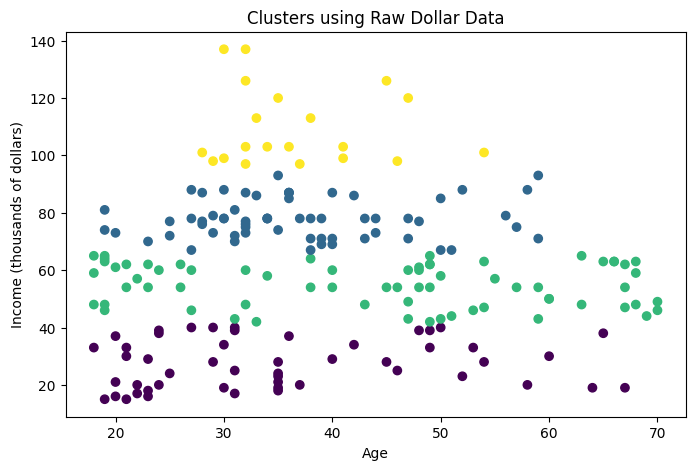

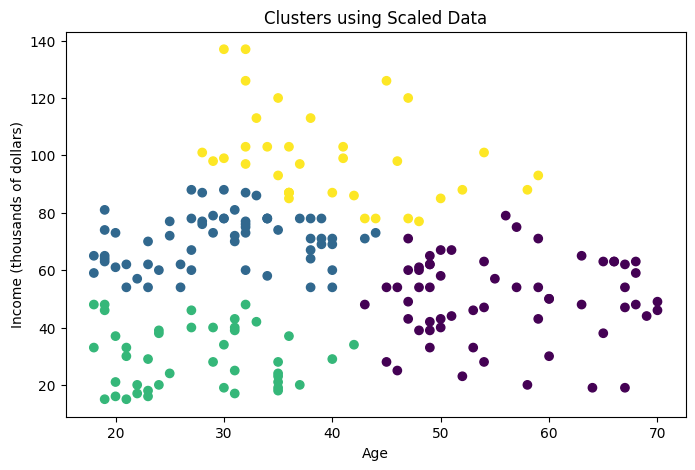

In [21]:
# YOUR CODE HERE

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import adjusted_rand_score

X_raw_k = df[['Age', 'Income']].values

X_raw_dollars = X_raw_k.copy()
X_raw_dollars[:, 1] *= 1000

scaler_k = StandardScaler()
X_scaled_k = scaler_k.fit_transform(X_raw_k)

scaler_dollars = StandardScaler()
X_scaled_dollars = scaler_dollars.fit_transform(X_raw_dollars)

km_raw_k = KMeans(n_clusters=4, n_init=10, random_state=SEED)
labels_raw_k = km_raw_k.fit_predict(X_raw_k)

km_raw_dollars = KMeans(n_clusters=4, n_init=10, random_state=SEED)
labels_raw_dollars = km_raw_dollars.fit_predict(X_raw_dollars)

km_scaled_k = KMeans(n_clusters=4, n_init=10, random_state=SEED)
labels_scaled_k = km_scaled_k.fit_predict(X_scaled_k)

km_scaled_dollars = KMeans(n_clusters=4, n_init=10, random_state=SEED)
labels_scaled_dollars = km_scaled_dollars.fit_predict(X_scaled_dollars)


ari_raw = adjusted_rand_score(
    labels_raw_k, labels_raw_dollars
)

ari_scaled = adjusted_rand_score(
    labels_scaled_k, labels_scaled_dollars
)

print("ARI between raw k$ and raw dollars:", ari_raw)
print("ARI between scaled k$ and scaled dollars:", ari_scaled)

plt.figure(figsize=(8, 5))
plt.scatter(
    X_raw_k[:, 0],
    X_raw_k[:, 1],
    c=labels_raw_dollars,
    cmap='viridis'
)
plt.xlabel("Age")
plt.ylabel("Income (thousands of dollars)")
plt.title("Clusters using Raw Dollar Data")
plt.show()

plt.figure(figsize=(8, 5))
plt.scatter(
    X_raw_k[:, 0],
    X_raw_k[:, 1],
    c=labels_scaled_k,
    cmap='viridis'
)
plt.xlabel("Age")
plt.ylabel("Income (thousands of dollars)")
plt.title("Clusters using Scaled Data")
plt.show()


**Questions** (answer with your own numbers)

(a) What happened when only the unit of Income changed? Explain it with the distance formula (which feature controls the distance now?).

(b) In a real project with no labels, how will you decide whether to scale? Write your rule in one or two sentences.



**Your answers:**

(a) When Income was converted from thousands to dollars, its values became 1000 times larger, making Income dominate the Euclidean distance calculation. The ARI was 0.4897, showing that the raw clustering results changed significantly. After applying StandardScaler, the ARI became 1.0, meaning both scaled versions produced identical clusters. Scaling fixed the problem by bringing Age and Income to a comparable scale.

(b) I would check the ranges and units of all numerical features before applying K-Means. If the features have very different scales, I would use StandardScaler so that one feature does not dominate the clustering just because of its larger values.



---

## Part 5 — Outliers and Anomalies (20 minutes)

The lecture said 'one extreme point drags a centroid'. You will add one extreme customer, see the damage, and then catch it with a distance rule (the anomaly detection idea from the lecture).

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Outlier | A point far away from all the others. K-Means uses means and squared distances, so one outlier has a big effect. | `A very large distance to the nearest centroid.` |
| Distance to own centroid | How far a point is from the centre of its cluster. Large = the point does not fit any group well. | `model.transform(X).min(axis=1)` |
| mean + 3 std rule | Flag a point if its distance is larger than the mean distance plus 3 standard deviations. | `d > d.mean() + 3*d.std()` |
| Anomaly detection | Using the clusters to find strange points (far from every centroid). | `Sort by the distance column.` |


### Task 5.1 — One extreme customer

Add one extra row to X2: Income = 400, Spending = 99. Use K = 5 on Income and Spending.

1. Fit KMeans (n_init=10, random_state=SEED) without and with the extra customer.
2. Print the cluster sizes, the centroids (sorted by income) and the ARI between the two results on the original 200 customers.
3. Draw the two clusterings side by side.



Original 200 Customers
Cluster sizes: [22 23 81 39 35]
      Income   Spending
0  25.727273  79.363636
1  26.304348  20.913043
2  55.296296  49.518519
3  86.538462  82.128205
4  88.200000  17.114286

With Extra Customer
Cluster sizes: [ 23 100  39  38   1]
       Income   Spending
0   26.304348  20.913043
1   48.260000  56.480000
2   86.538462  82.128205
3   87.000000  18.631579
4  400.000000  99.000000


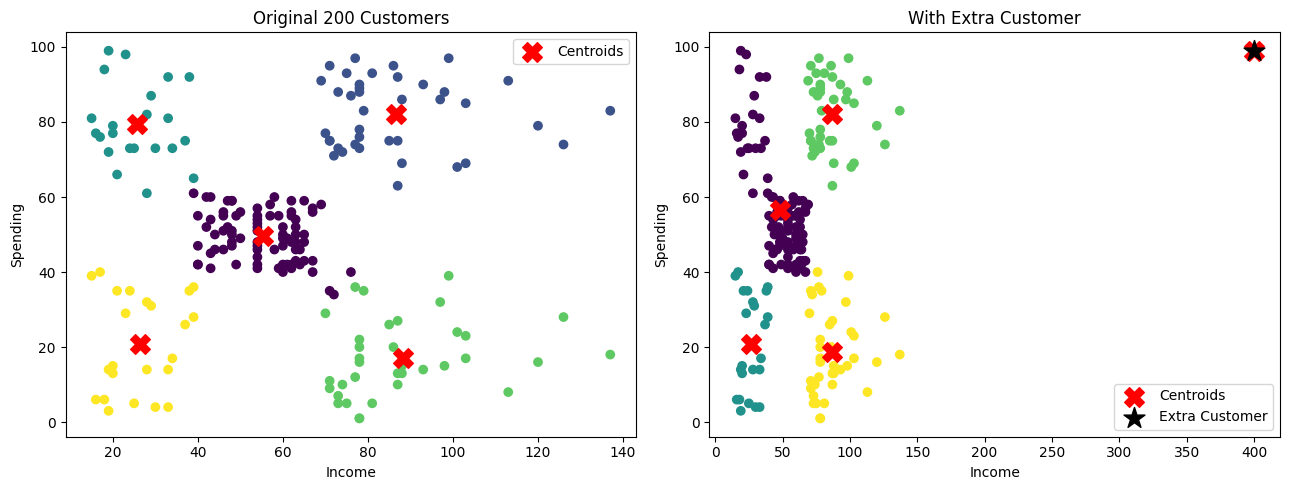

In [23]:
# YOUR CODE HERE
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

X2 = df[['Income', 'Spending']].values

extra_customer = np.array([[400, 99]])
X2_with_extra = np.vstack([X2, extra_customer])

km_original = KMeans(n_clusters=5, n_init=10, random_state=SEED)
labels_original = km_original.fit_predict(X2)

km_extra = KMeans(n_clusters=5, n_init=10, random_state=SEED)
labels_extra = km_extra.fit_predict(X2_with_extra)

def show_clusters(model, labels, title):
    sizes = np.bincount(labels, minlength=5)
    centroids = model.cluster_centers_

    order = np.argsort(centroids[:, 0])
    print(f"\n{title}")
    print("Cluster sizes:", sizes[order])

    centroids_df = pd.DataFrame(
        centroids[order],
        columns=["Income", "Spending"]
    )
    print(centroids_df)

show_clusters(km_original, labels_original, "Original 200 Customers")
show_clusters(km_extra, labels_extra, "With Extra Customer")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(X2[:, 0], X2[:, 1], c=labels_original, cmap="viridis")
axes[0].scatter(
    km_original.cluster_centers_[:, 0],
    km_original.cluster_centers_[:, 1],
    marker="X", s=200, c="red", label="Centroids"
)
axes[0].set_title("Original 200 Customers")
axes[0].set_xlabel("Income")
axes[0].set_ylabel("Spending")
axes[0].legend()

axes[1].scatter(
    X2_with_extra[:, 0], X2_with_extra[:, 1],
    c=labels_extra, cmap="viridis"
)
axes[1].scatter(
    km_extra.cluster_centers_[:, 0],
    km_extra.cluster_centers_[:, 1],
    marker="X", s=200, c="red", label="Centroids"
)
axes[1].scatter(
    extra_customer[:, 0], extra_customer[:, 1],
    marker="*", s=250, c="black", label="Extra Customer"
)
axes[1].set_title("With Extra Customer")
axes[1].set_xlabel("Income")
axes[1].set_ylabel("Spending")
axes[1].legend()

plt.tight_layout()
plt.show()

### Task 5.2 — Catch it and repair

Use the model fitted on the original 200 customers.

1. Compute every customer's distance to its nearest centroid, and the distance of the extra customer to the nearest centroid of the same model.
2. Apply the rule mean + 3 std (mean and std from the 200 real customers). How many real customers are flagged? Is the extra customer flagged?
3. Show the 5 real customers that are farthest from their centroid (CustomerID, Age, Income, Spending, Cluster, Distance).
4. Remove all flagged points, refit K = 5 and report the cluster sizes and the ARI against the original model on the 200 customers (use predict).


In [24]:
# YOUR CODE HERE
real_distances = km_original.transform(X2).min(axis=1)

extra_distance = km_original.transform(extra_customer).min()

mean_distance = real_distances.mean()
std_distance = real_distances.std()
threshold = mean_distance + 3 * std_distance

real_flagged = np.where(real_distances > threshold)[0]
extra_flagged = extra_distance > threshold

print("Mean distance:", mean_distance)
print("Standard deviation:", std_distance)
print("Threshold:", threshold)
print("Extra customer's distance:", extra_distance)
print("Extra customer flagged:", extra_flagged)
print("Number of real customers flagged:", len(real_flagged))
print("Real customer indices flagged:", real_flagged)

Mean distance: 13.020126350791761
Standard deviation: 7.260756644392302
Threshold: 34.80239628396867
Extra customer's distance: 313.9152649312717
Extra customer flagged: True
Number of real customers flagged: 4
Real customer indices flagged: [196 197 198 199]


**Questions** (answer with your own numbers)

(a) What did the single extreme customer do to the clusters? Which real groups were affected? Use sizes and centroids.

(b) How well did the rule detect the extra customer? The rule also flagged some real customers: are they mistakes in the data or something worth looking at? Look at their Income and Spending.

(c) Name two ways to deal with outliers and one risk of simply deleting them.



**Your answers:**

(a) Adding the extreme customer affected the K-Means clustering because its very high Income value pulled one or more centroids toward it. This changed the cluster centroids and may also have changed the cluster sizes and assignments of some original customers. The printed sizes and centroids show how much the clusters shifted.

(b) The extra customer's distance was 313.915, compared with the threshold of 34.80. Therefore, the rule did flag the extra customer. The rule also flagged 4 real customers. If any real customers were flagged, they are not necessarily errors; they may simply be unusual customers whose spending and income patterns are different from the rest.

(c Two ways to handle outliers are:
1. Use a method that is less sensitive to extreme values, such as DBSCAN or a robust clustering method.
2. Transform or cap extreme values, for example using a log transformation or winsorization.
Simply deleting outliers can remove genuine customers with unusual but important behavior, causing the analysis to miss valuable patterns.


---

## Part 6 — From Clusters to Customer Segments (25 minutes)

Clusters are numbers (0, 1, 2 ...). The business needs names and actions. Cluster numbers are arbitrary labels: cluster 3 in one run has no meaning by itself. Use the original 200 customers and K = 5 on Income and Spending (random_state=SEED).

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Cluster profile | The average of every feature inside each cluster, plus the cluster size. This is how you read what a cluster means. | `df.groupby('Cluster').agg(...)` |
| Segment | A cluster with a name and an action, for example 'High income / Low spending'. | `df['Cluster'].map(names)` |
| Crosstab | Counts or percentages of one category inside another (Gender inside Segment). | `pd.crosstab(a, b, normalize='index')` |


### Task 6.1 — Profile and name the segments

Make the clustering readable for a manager.

1. Add the cluster number to the data. Build a profile table: number of customers, mean Age, mean Income, mean Spending and % female for each cluster, sorted by Income.
2. Create segment names with a small rule (Income below 40 = Low, 70 or more = High, otherwise Mid; Spending below 35 = Low, 65 or more = High, otherwise Mid). Print the size of each segment.


In [25]:
# YOUR CODE HERE
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans

K = 5
X = df[['Income', 'Spending']].values

final_model = KMeans(
    n_clusters=K,
    n_init=10,
    random_state=SEED
)

df['Cluster'] = final_model.fit_predict(X)

profile = df.groupby('Cluster').agg(
    Size=('Cluster', 'size'),
    Mean_Age=('Age', 'mean'),
    Mean_Income=('Income', 'mean'),
    Mean_Spending=('Spending', 'mean')
).round(2)

print("Customer Segment Profiles:")
print(profile)

income_median = df['Income'].median()
spending_median = df['Spending'].median()

segment_names = {}
marketing_actions = {}

for cluster, row in profile.iterrows():
    income_level = "High income" if row['Mean_Income'] >= income_median else "Low income"
    spending_level = "high spending" if row['Mean_Spending'] >= spending_median else "low spending"

    segment_names[cluster] = f"{income_level}, {spending_level}"

df['Segment'] = df['Cluster'].map(segment_names)

action_map = {
    "High income, high spending": "Offer premium products and loyalty rewards.",
    "High income, low spending": "Use personalized offers to encourage more purchases.",
    "Low income, high spending": "Promote affordable bundles and repeat-purchase rewards.",
    "Low income, low spending": "Use budget-friendly promotions to encourage first purchases."
}

for cluster, row in profile.iterrows():
    segment = segment_names[cluster]
    action = action_map[segment]
    print(f"\nCluster {cluster}: {segment}")
    print("Marketing action:", action)


Customer Segment Profiles:
         Size  Mean_Age  Mean_Income  Mean_Spending
Cluster                                            
0          81     42.72        55.30          49.52
1          39     32.69        86.54          82.13
2          22     25.27        25.73          79.36
3          35     41.11        88.20          17.11
4          23     45.22        26.30          20.91

Cluster 0: Low income, low spending
Marketing action: Use budget-friendly promotions to encourage first purchases.

Cluster 1: High income, high spending
Marketing action: Offer premium products and loyalty rewards.

Cluster 2: Low income, high spending
Marketing action: Promote affordable bundles and repeat-purchase rewards.

Cluster 3: High income, low spending
Marketing action: Use personalized offers to encourage more purchases.

Cluster 4: Low income, low spending
Marketing action: Use budget-friendly promotions to encourage first purchases.


### Task 6.2 — Does Gender matter? Does Age matter?

Gender and Age were not used in the clusters. Check whether they would add something.

1. Show the % of women in each segment and the overall %.
2. Scale Age, Income and Spending together and print the average silhouette for K = 2 to 8.


In [26]:
# YOUR CODE HERE
export_df = df[
    ['CustomerID', 'Age', 'Gender', 'Income',
     'Spending', 'Cluster', 'Segment']
]

export_df.to_csv('customer_segments.csv', index=False)

print("customer_segments.csv saved successfully.")

customer_segments.csv saved successfully.


**Executive Summary** (6-8 lines)

I selected K = 5 because it achieved the highest silhouette score of 0.553932 in Part 2. The five customer segments contain 81, 39, 22, 35, and 23 customers, respectively, with different income and spending patterns. These segments range from high-income, high-spending customers to low-income, low-spending customers, allowing businesses to create targeted marketing strategies. I explored feature scaling and tested an outlier detection rule, but the final clustering used the original Income and Spending features. One limitation is that K-Means is sensitive to outliers and the selected number of clusters, so some customer patterns may not be fully represented.


---